# Multiclass - Class Weight (imbalanced classes)

In [4]:
import pandas as pd
import numpy as np
from collections import Counter
from sklearn.datasets import make_classification  # synthetic data (fake data)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
from sklearn.model_selection import GridSearchCV

In [5]:
x ,y = make_classification(
    n_samples = 12000,
    n_features = 12,
    n_redundant = 2,
    n_informative = 8,
    n_classes = 4,
    n_clusters_per_class = 1,
    weights = [0.6,0.2,0.15,0.05],# creating imbalance classes
    random_state = 42
)

<Axes: xlabel='0', ylabel='1'>

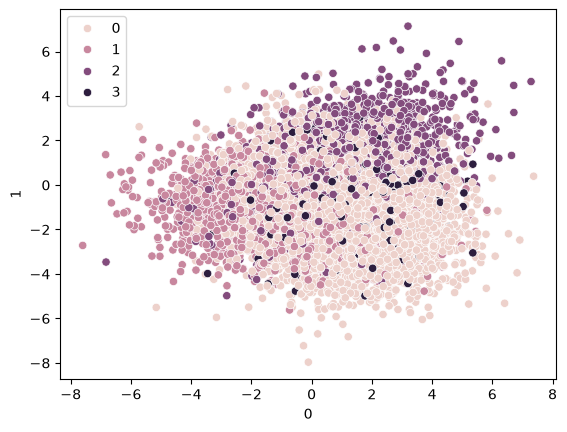

In [18]:
# scatter plot
# to visualize the classes inside the dependent variable - y
sns.scatterplot(
    x = pd.DataFrame(x)[0],
    y = pd.DataFrame(x)[1],
    hue = y
)

# types of features :

1. informative : n_informative = 3 means, outoff all features in the dataset , this 3 feature have more correlation and help to predict the dependent variable ->  like highly useable.

2. n_redundant : n_rendundant = 3 means, it create 3 columns/features copying from the other 3 columns/features and it have same data and same meaning. Because, it simulate the real world scenario/data, in real world some features have the same meaning and high correlation to replica the real one. it adds correlation, multicollenearity, test robustness.

3. rest of 6 columns : it contains the noise data. these columns are doesn't contribute to the machine training/learning. like unwanted data.no relation to target and mainly makes problem solving harder.

# n_clusters_per_class :

1. this cluster is all about the separation and position of classes spliting, whether the data want to replica the real world scenario or not.

2. this clusters = 1, make the classes into separate group like a tightly coupled rather than scattering.

3. create tight group - easy to prediction

4. with cluster = 2 or more,  the classes are in scattered position and more complex to predict. like it will collage one over another. so this is replica the real life scenario.

In [6]:
print(Counter(y)) # perfectly imbalanced classes.

Counter({np.int64(0): 7160, np.int64(1): 2412, np.int64(2): 1809, np.int64(3): 619})


In [7]:
# data spliting :

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    stratify=y,
    random_state = 42
)

In [8]:
# without hyperparameter tuning : just with logistic regression model alone

In [9]:
model = LogisticRegression(max_iter = 1000)
model.fit(x_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [10]:
y_pred = model.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95      1790
           1       0.77      0.82      0.79       603
           2       0.77      0.77      0.77       452
           3       0.61      0.25      0.35       155

    accuracy                           0.87      3000
   macro avg       0.77      0.70      0.72      3000
weighted avg       0.86      0.87      0.86      3000



In [11]:
# with hyperparameter tuning

In [12]:
model = LogisticRegression(max_iter = 1000)

In [13]:
# arguments settings :

penalty = ['l1', 'l2', 'elasticnet']
c = [0.01,1,0.1,5]
solver = ['lbfgs']
class_weight = [None, 'balanced', {0:1, 1:2, 2:3, 3:6},{0:1,1:3,2:4,3:10}]

In [14]:
len(class_weight)

4

In [15]:
# the combinations for model training :

print(f"Total Model Fits : ", 3*4*1*4)

Total Model Fits :  48


In [16]:
# param values :

params = dict(
    penalty = penalty,
    C = c,
    solver = solver,
    class_weight = class_weight
)

In [17]:
# gridsearchcv engine :

grid = GridSearchCV(
    estimator = model,
    param_grid=params,
    scoring = 'precision_macro', # "scoring = precision_macro" is FP is priority /  "scoring = recall_macro"is FN is our priority / for balanced mathematicall score is "scoring = f1"
    cv = 5,
    n_jobs = -1 # this tell my computer to use all available CPU cores to run the grid search at same time.
                # instead of checking one hyperparameter combinations at a time, it checks multiple combination in parallel.
                # this speed up the training process
)

In [61]:
grid.fit(x_train, y_train)

C:\Users\Vignesh R\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
160 fits failed out of a total of 240.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
80 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\Vignesh R\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\Users\Vignesh R\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\User

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...max_iter=1000)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 1, ...], 'class_weight': [None, 'balanced', ...], 'penalty': ['l1', 'l2', ...], 'solver': ['lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'precision_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"ver

In [34]:
# the best model by iterating the multiple combinations :

grid.best_params_

{'C': 1, 'class_weight': None, 'penalty': 'l2', 'solver': 'lbfgs'}

In [36]:
# accuracy score

best_model = grid.best_estimator_
y_pred = best_model.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95      1790
           1       0.77      0.82      0.79       603
           2       0.77      0.77      0.77       452
           3       0.61      0.25      0.35       155

    accuracy                           0.87      3000
   macro avg       0.77      0.70      0.72      3000
weighted avg       0.86      0.87      0.86      3000



In [62]:
# precision score :

grid.best_params_

{'C': 0.01, 'class_weight': None, 'penalty': 'l2', 'solver': 'lbfgs'}

In [63]:
# Higher Precision = Fewer false alarms ("0"s wrongly called "1"s).
# Fewer false alarms = Lower False Positives (FP).

best_model = grid.best_estimator_
y_pred = best_model.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.93      0.97      0.95      1790
           1       0.77      0.82      0.79       603
           2       0.77      0.76      0.77       452
           3       0.61      0.20      0.30       155

    accuracy                           0.87      3000
   macro avg       0.77      0.69      0.70      3000
weighted avg       0.86      0.87      0.86      3000



In [47]:
# recall score :

grid.best_params_

{'C': 1,
 'class_weight': {0: 1, 1: 3, 2: 4, 3: 10},
 'penalty': 'l2',
 'solver': 'lbfgs'}

In [49]:
# Higher Recall = Fewer missed "1"s.
# Fewer missed "1"s = Lower False Negatives.

best_model = grid.best_estimator_
y_pred = best_model.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.97      0.84      0.90      1790
           1       0.81      0.78      0.80       603
           2       0.70      0.77      0.73       452
           3       0.29      0.66      0.41       155

    accuracy                           0.81      3000
   macro avg       0.69      0.77      0.71      3000
weighted avg       0.86      0.81      0.83      3000

